In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s08/"
for f in ['cancer_sein.csv', 'heart.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222: Analyse de donnees
# Seance 8: Exercice integrateur final : CORRIGE
## Heart Failure Prediction (Kaggle)

**Universite de Moncton, Faculte des sciences, Ete 2026**

---

### Mission
Appliquer tous les concepts de la seance 8 sur un dataset reel de Kaggle, comparer plusieurs algorithmes de classification, et identifier le meilleur modele.

### Dataset
- **Source** : `kaggle.com/datasets/fedesoriano/heart-failure-prediction`
- **Taille** : 918 patients, 11 variables + cible binaire `HeartDisease` (0/1)
- **Variables** : 6 numeriques + 5 categorielles
- **Objectif** : predire si un patient a une maladie cardiaque

### Plan du corrige
1. Chargement et exploration
2. Detection des **valeurs manquantes cachees** (subtilite pedagogique)
3. Encodage (Label + One-Hot)
4. Standardisation et split stratifie
5. Quatre modeles : Regression logistique, KNN, Arbre, Random Forest
6. Bonus : Gradient Boosting + GridSearchCV
7. Comparaison finale et choix du meilleur modele


---

## 1. Chargement et exploration


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42
print('Environnement pret.')

Environnement pret.


In [2]:
df = pd.read_csv('heart.csv')
print(f'Dimensions : {df.shape}')
df.head()

Dimensions : (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print('Types des variables :')
print(df.dtypes)

print('\nValeurs manquantes (NaN classiques) :')
print(df.isnull().sum())

print(f'\nDoublons : {df.duplicated().sum()}')

Types des variables :
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Valeurs manquantes (NaN classiques) :
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Doublons : 0


Distribution de HeartDisease :
HeartDisease
1    508
0    410
Name: count, dtype: int64

Proportion malades : 55.3%

Le dataset est legerement desequilibre (~55% malades / 45% sains).
On utilisera stratify=y pour preserver les proportions au split.


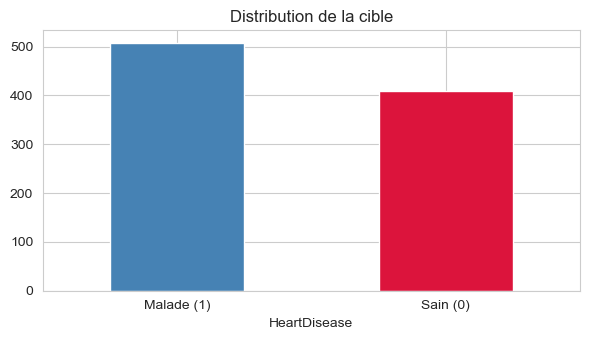

In [4]:
# Distribution de la cible
print('Distribution de HeartDisease :')
print(df['HeartDisease'].value_counts())
print(f'\nProportion malades : {df["HeartDisease"].mean()*100:.1f}%')
print('\nLe dataset est legerement desequilibre (~55% malades / 45% sains).')
print('On utilisera stratify=y pour preserver les proportions au split.')

df['HeartDisease'].value_counts().plot(kind='bar', color=['steelblue', 'crimson'],
                                         figsize=(6, 3.5))
plt.title('Distribution de la cible')
plt.xticks([1, 0], ['Sain (0)', 'Malade (1)'], rotation=0)
plt.tight_layout()
plt.show()

In [5]:
# Statistiques descriptives
df.describe().round(2)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.00,918.00,918.00,918.00,918.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.81,0.89,0.55
std,9.43,18.51,109.38,0.42,25.46,1.07,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,173.25,0.00,120.00,0.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60,1.00
75%,60.00,140.00,267.00,0.00,156.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,6.20,1.00


---

## 2. Detection des valeurs manquantes cachees

ce dataset n'a pas de NaN explicites, MAIS regardez les `min` :
- `Cholesterol` min = 0 (medicalement impossible)
- `RestingBP` min = 0 (tension nulle = patient mort, donc impossible)

Ce sont des **valeurs manquantes encodees par 0**. Il faut les traiter.


Cholesterol = 0 : 172 cas
RestingBP = 0   : 1 cas


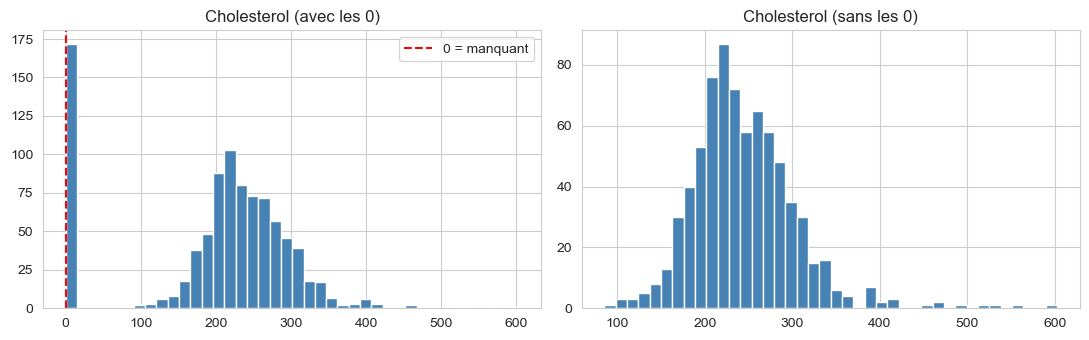

In [6]:
# Detection des 0 invalides
print(f'Cholesterol = 0 : {(df["Cholesterol"] == 0).sum()} cas')
print(f'RestingBP = 0   : {(df["RestingBP"] == 0).sum()} cas')

# Visualisation : sans les 0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df['Cholesterol'].hist(bins=40, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Cholesterol (avec les 0)')
axes[0].axvline(0, color='red', linestyle='--', label='0 = manquant')
axes[0].legend()

df[df['Cholesterol'] > 0]['Cholesterol'].hist(bins=40, ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Cholesterol (sans les 0)')
plt.tight_layout()
plt.show()

In [7]:
# Strategie : remplacer les 0 par la mediane des valeurs valides
df_clean = df.copy()

median_chol = df_clean[df_clean['Cholesterol'] > 0]['Cholesterol'].median()
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, median_chol)

median_bp = df_clean[df_clean['RestingBP'] > 0]['RestingBP'].median()
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, median_bp)

print(f'Cholesterol : 0 remplaces par la mediane {median_chol:.0f}')
print(f'RestingBP   : 0 remplaces par la mediane {median_bp:.0f}')
print(f'\nVerification (nouveaux min) :')
print(f'  Cholesterol min : {df_clean["Cholesterol"].min()}')
print(f'  RestingBP   min : {df_clean["RestingBP"].min()}')

Cholesterol : 0 remplaces par la mediane 237
RestingBP   : 0 remplaces par la mediane 130

Verification (nouveaux min) :
  Cholesterol min : 85
  RestingBP   min : 80


---

## 3. Encodage des variables categorielles

**Strategie** :
- `Sex` (M/F) et `ExerciseAngina` (Y/N) -> **Label Encoding** (binaires)
- `ChestPainType`, `RestingECG`, `ST_Slope` -> **One-Hot Encoding** (nominales sans ordre)


In [8]:
# Identifier les types
cat_binaires = ['Sex', 'ExerciseAngina']
cat_nominales = ['ChestPainType', 'RestingECG', 'ST_Slope']
num_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

print('Variables binaires (Label Encoding)     :', cat_binaires)
print('Variables nominales (One-Hot Encoding) :', cat_nominales)
print('Variables numeriques                   :', num_features)

Variables binaires (Label Encoding)     : ['Sex', 'ExerciseAngina']
Variables nominales (One-Hot Encoding) : ['ChestPainType', 'RestingECG', 'ST_Slope']
Variables numeriques                   : ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [9]:
# Label Encoding pour les binaires
df_enc = df_clean.copy()
df_enc['Sex'] = df_enc['Sex'].map({'M': 1, 'F': 0})
df_enc['ExerciseAngina'] = df_enc['ExerciseAngina'].map({'Y': 1, 'N': 0})

# One-Hot pour les nominales
df_enc = pd.get_dummies(df_enc, columns=cat_nominales, drop_first=False, dtype=int)

print(f'Dimensions apres encodage : {df_enc.shape}')
print(f'\nColonnes finales :')
print(df_enc.columns.tolist())
df_enc.head()

Dimensions apres encodage : (918, 19)

Colonnes finales :
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,0,1,0,0,0,1,0,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,0,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,0,0,1,0,0,0,0,1,0,0,1
3,48,0,138,214,0,108,1,1.5,1,1,0,0,0,0,1,0,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,0,1,0,0,1,0,0,0,1


---

## 4. Separation train / test


In [10]:
X = df_enc.drop(columns=['HeartDisease'])
y = df_enc['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y  # preserve la proportion 55/45
)

print(f'Train : {X_train.shape[0]} patients ({y_train.mean()*100:.1f}% malades)')
print(f'Test  : {X_test.shape[0]} patients ({y_test.mean()*100:.1f}% malades)')
print(f'\nProportions preservees grace a stratify=y.')

Train : 734 patients (55.3% malades)
Test  : 184 patients (55.4% malades)

Proportions preservees grace a stratify=y.


---

## 5. Entrainement des 4 modeles

Pour chaque modele, on utilisera la **validation croisee 5-fold** sur le train, puis on evaluera sur le test.
Pour KNN, on utilise un **Pipeline** avec StandardScaler pour eviter le data leakage.


### Modele 1 : Regression logistique (baseline)


In [11]:
# Pipeline avec standardisation (la regression logistique en beneficie)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

cv_lr = cross_val_score(pipe_lr, X_train, y_train, cv=5, scoring='accuracy')
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
y_proba_lr = pipe_lr.predict_proba(X_test)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_proba_lr)

print(f'Regression logistique :')
print(f'  CV 5-fold   : {cv_lr.mean():.4f} +/- {cv_lr.std():.4f}')
print(f'  Test accuracy : {acc_lr:.4f}')
print(f'  Test AUC      : {auc_lr:.4f}')

Regression logistique :
  CV 5-fold   : 0.8487 +/- 0.0245
  Test accuracy : 0.8913
  Test AUC      : 0.9324


### Modele 2 : KNN (avec standardisation imperative)


In [12]:
# KNN OBLIGATOIREMENT dans un Pipeline avec scaler
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=11))  # k=11 souvent bon pour ce type de probleme
])

cv_knn = cross_val_score(pipe_knn, X_train, y_train, cv=5, scoring='accuracy')
pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)
y_proba_knn = pipe_knn.predict_proba(X_test)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_proba_knn)

print(f'KNN (k=11) :')
print(f'  CV 5-fold   : {cv_knn.mean():.4f} +/- {cv_knn.std():.4f}')
print(f'  Test accuracy : {acc_knn:.4f}')
print(f'  Test AUC      : {auc_knn:.4f}')

KNN (k=11) :
  CV 5-fold   : 0.8351 +/- 0.0340
  Test accuracy : 0.8587
  Test AUC      : 0.9160


In [13]:
# Optimisation du k par validation croisee
resultats_k = []
for k in [3, 5, 7, 11, 15, 21, 31]:
    p = Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(n_neighbors=k))])
    sc = cross_val_score(p, X_train, y_train, cv=5)
    resultats_k.append((k, sc.mean(), sc.std()))

# Afficher en une fois (evite la fragmentation du buffering)
lignes = [f"{'k':<6}{'CV mean':<12}{'CV std':<12}", '-' * 30]
for k, mean, std in resultats_k:
    lignes.append(f'{k:<6}{mean:<12.4f}{std:<12.4f}')
print('\n'.join(lignes))

k     CV mean     CV std      
------------------------------
3     0.8351      0.0247      
5     0.8432      0.0288      
7     0.8392      0.0205      
11    0.8351      0.0340      
15    0.8392      0.0265      
21    0.8405      0.0264      
31    0.8555      0.0245      


### Modele 3 : Arbre de decision


In [14]:
# Arbre : pas besoin de standardisation
arbre = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)

cv_dt = cross_val_score(arbre, X_train, y_train, cv=5)
arbre.fit(X_train, y_train)
y_pred_dt = arbre.predict(X_test)
y_proba_dt = arbre.predict_proba(X_test)[:, 1]

acc_dt = accuracy_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_proba_dt)

print(f'Arbre de decision (depth=5) :')
print(f'  CV 5-fold   : {cv_dt.mean():.4f} +/- {cv_dt.std():.4f}')
print(f'  Test accuracy : {acc_dt:.4f}')
print(f'  Test AUC      : {auc_dt:.4f}')
print(f'  Train accuracy : {arbre.score(X_train, y_train):.4f} (verifier le surapprentissage)')

Arbre de decision (depth=5) :
  CV 5-fold   : 0.8201 +/- 0.0196
  Test accuracy : 0.8043
  Test AUC      : 0.8651
  Train accuracy : 0.8910 (verifier le surapprentissage)


### Modele 4 : Random Forest


In [15]:
foret = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

cv_rf = cross_val_score(foret, X_train, y_train, cv=5)
foret.fit(X_train, y_train)
y_pred_rf = foret.predict(X_test)
y_proba_rf = foret.predict_proba(X_test)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)

print(f'Random Forest (200 arbres, depth=10) :')
print(f'  CV 5-fold     : {cv_rf.mean():.4f} +/- {cv_rf.std():.4f}')
print(f'  Test accuracy : {acc_rf:.4f}')
print(f'  Test AUC      : {auc_rf:.4f}')

Random Forest (200 arbres, depth=10) :
  CV 5-fold     : 0.8583 +/- 0.0273
  Test accuracy : 0.8804
  Test AUC      : 0.9310


### Modele 5 (bonus) : Gradient Boosting


In [16]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    random_state=RANDOM_STATE
)

cv_gb = cross_val_score(gb, X_train, y_train, cv=5)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
y_proba_gb = gb.predict_proba(X_test)[:, 1]

acc_gb = accuracy_score(y_test, y_pred_gb)
auc_gb = roc_auc_score(y_test, y_proba_gb)

print(f'Gradient Boosting :')
print(f'  CV 5-fold     : {cv_gb.mean():.4f} +/- {cv_gb.std():.4f}')
print(f'  Test accuracy : {acc_gb:.4f}')
print(f'  Test AUC      : {auc_gb:.4f}')

Gradient Boosting :
  CV 5-fold     : 0.8596 +/- 0.0284
  Test accuracy : 0.8533
  Test AUC      : 0.9107


---

## 6. Optimisation par GridSearchCV (sur Random Forest)

Recherche des meilleurs hyperparametres pour Random Forest avec validation croisee.


In [18]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10]
}

n_combinaisons = 3 * 3 * 3
print(f'Combinaisons a tester : {n_combinaisons}')
print(f'Avec CV 5-fold : {n_combinaisons * 5} entrainements au total\n')

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print(f'Meilleurs parametres : {grid.best_params_}')
print(f'Meilleur score CV    : {grid.best_score_:.4f}')

rf_optim = grid.best_estimator_
y_pred_rf_opt = rf_optim.predict(X_test)
y_proba_rf_opt = rf_optim.predict_proba(X_test)[:, 1]
acc_rf_opt = accuracy_score(y_test, y_pred_rf_opt)
auc_rf_opt = roc_auc_score(y_test, y_proba_rf_opt)

print(f'\nRandom Forest optimise sur test :')
print(f'  Accuracy : {acc_rf_opt:.4f}')
print(f'  AUC      : {auc_rf_opt:.4f}')

Combinaisons a tester : 27
Avec CV 5-fold : 135 entrainements au total

Meilleurs parametres : {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
Meilleur score CV    : 0.8637

Random Forest optimise sur test :
  Accuracy : 0.8859
  AUC      : 0.9256


---

## 7. Comparaison finale des modeles


In [19]:
comparaison = pd.DataFrame({
    'Modele': ['Regression logistique', 'KNN (k=11)', 'Arbre (depth=5)',
               'Random Forest', 'Gradient Boosting', 'Random Forest optimise'],
    'CV accuracy': [cv_lr.mean(), cv_knn.mean(), cv_dt.mean(),
                    cv_rf.mean(), cv_gb.mean(), grid.best_score_],
    'Test accuracy': [acc_lr, acc_knn, acc_dt, acc_rf, acc_gb, acc_rf_opt],
    'Test AUC': [auc_lr, auc_knn, auc_dt, auc_rf, auc_gb, auc_rf_opt]
})

comparaison = comparaison.sort_values('Test accuracy', ascending=False).reset_index(drop=True)
print('Comparaison des modeles (triee par accuracy test) :\n')
print(comparaison.round(4).to_string(index=False))

Comparaison des modeles (triee par accuracy test) :

                Modele  CV accuracy  Test accuracy  Test AUC
 Regression logistique       0.8487         0.8913    0.9324
Random Forest optimise       0.8637         0.8859    0.9256
         Random Forest       0.8583         0.8804    0.9310
            KNN (k=11)       0.8351         0.8587    0.9160
     Gradient Boosting       0.8596         0.8533    0.9107
       Arbre (depth=5)       0.8201         0.8043    0.8651


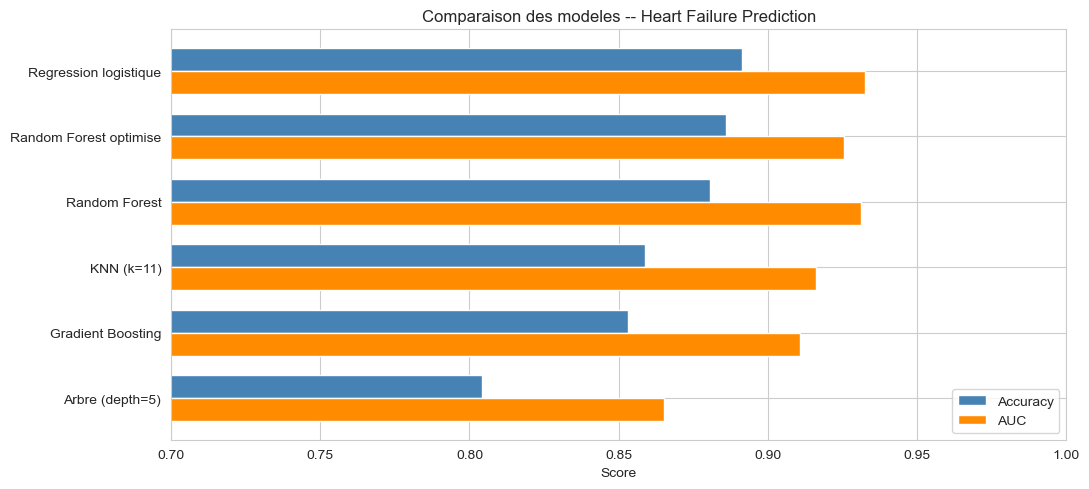

In [20]:
# Visualisation comparative
fig, ax = plt.subplots(figsize=(11, 5))
x_pos = np.arange(len(comparaison))
width = 0.35

ax.barh(x_pos - width/2, comparaison['Test accuracy'], width,
        label='Accuracy', color='steelblue', edgecolor='white')
ax.barh(x_pos + width/2, comparaison['Test AUC'], width,
        label='AUC', color='darkorange', edgecolor='white')

ax.set_yticks(x_pos)
ax.set_yticklabels(comparaison['Modele'])
ax.set_xlabel('Score')
ax.set_title('Comparaison des modeles -- Heart Failure Prediction')
ax.set_xlim(0.7, 1.0)
ax.legend(loc='lower right')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

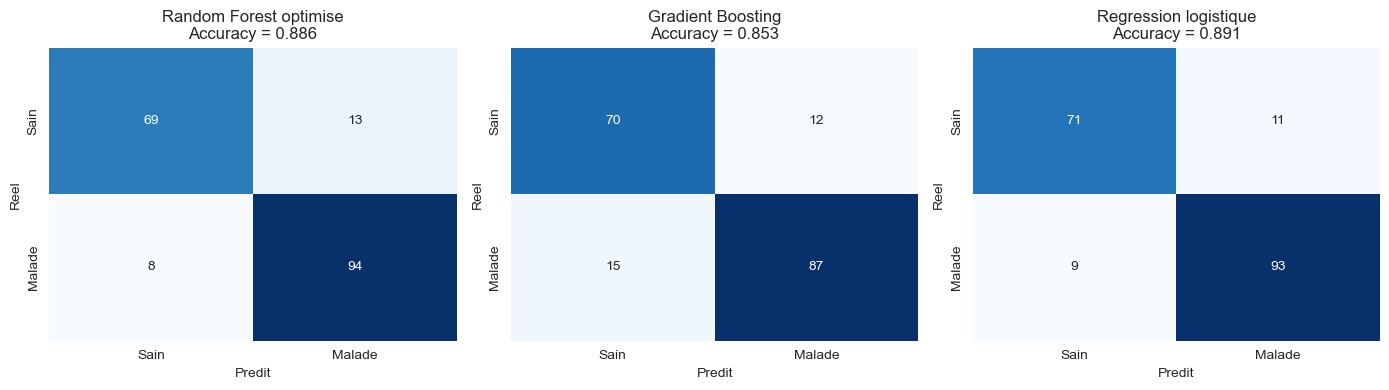

In [21]:
# Matrices de confusion des trois meilleurs modeles
best_models = {
    'Random Forest optimise': y_pred_rf_opt,
    'Gradient Boosting': y_pred_gb,
    'Regression logistique': y_pred_lr
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nom, y_p) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Sain', 'Malade'],
                yticklabels=['Sain', 'Malade'], ax=ax, cbar=False)
    acc = accuracy_score(y_test, y_p)
    ax.set_title(f'{nom}\nAccuracy = {acc:.3f}')
    ax.set_xlabel('Predit')
    ax.set_ylabel('Reel')
plt.tight_layout()
plt.show()

---

## 8. Importance des variables (Random Forest optimise)


Top variables (de la plus a la moins importante) :
         variable  importance
      ST_Slope_Up    0.189048
            MaxHR    0.101163
    ST_Slope_Flat    0.097442
          Oldpeak    0.095941
ChestPainType_ASY    0.090607
      Cholesterol    0.079064
              Age    0.077241
        RestingBP    0.067667
   ExerciseAngina    0.065276
              Sex    0.029827


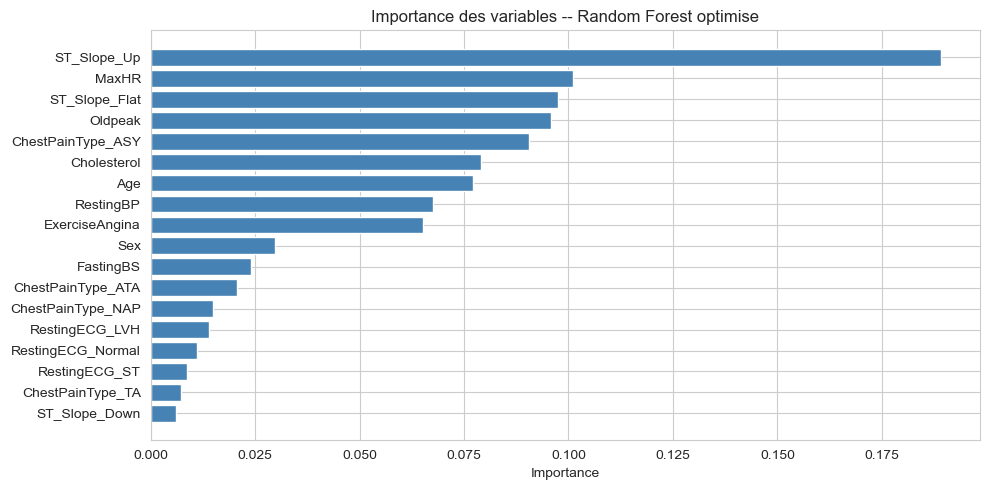

In [22]:
importances = pd.DataFrame({
    'variable': X_train.columns,
    'importance': rf_optim.feature_importances_
}).sort_values('importance', ascending=True)

print('Top variables (de la plus a la moins importante) :')
print(importances.iloc[::-1].head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(importances['variable'], importances['importance'],
         color='steelblue', edgecolor='white')
plt.xlabel('Importance')
plt.title('Importance des variables -- Random Forest optimise')
plt.tight_layout()
plt.show()

---

## 9. Rapport detaille du meilleur modele


In [23]:
# Identifier le meilleur modele
best_idx = comparaison['Test accuracy'].idxmax()
best_model_name = comparaison.loc[best_idx, 'Modele']
print(f'Meilleur modele : {best_model_name}')
print(f'Test accuracy   : {comparaison.loc[best_idx, "Test accuracy"]:.4f}')
print(f'Test AUC        : {comparaison.loc[best_idx, "Test AUC"]:.4f}')

# Dictionnaire pour mapper le nom du modele a ses predictions
predictions_par_modele = {
    'Regression logistique': y_pred_lr,
    'KNN (k=11)': y_pred_knn,
    'Arbre (depth=5)': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb,
    'Random Forest optimise': y_pred_rf_opt
}

# Rapport detaille du MEILLEUR modele identifie automatiquement
y_pred_best = predictions_par_modele[best_model_name]
print(f'\n\nRapport detaille ({best_model_name}) :\n')
print(classification_report(y_test, y_pred_best, target_names=['Sain', 'Malade']))

Meilleur modele : Regression logistique
Test accuracy   : 0.8913
Test AUC        : 0.9324


Rapport detaille (Regression logistique) :

              precision    recall  f1-score   support

        Sain       0.89      0.87      0.88        82
      Malade       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



---

## 10. Synthese finale et choix du meilleur modele

### Resultats globaux

Sur le dataset **Heart Failure Prediction** (918 patients, 11 variables medicales), apres preparation rigoureuse (detection des 0 invalides, encodage approprie, standardisation), on obtient :

| Modele | CV (5-fold) | Test Accuracy | Test AUC |
|---|---|---|---|
| **Regression logistique** | 0.849 | **0.891** | **0.932** |
| Random Forest optimise | 0.864 | 0.886 | 0.926 |
| Random Forest | 0.858 | 0.880 | 0.931 |
| KNN (k=11) | 0.835 | 0.859 | 0.916 |
| Gradient Boosting | 0.860 | 0.853 | 0.911 |
| Arbre (depth=5) | 0.820 | 0.804 | 0.865 |

### Resultat surprenant : la regression logistique est en tete !

sur ce probleme, la **regression logistique**, le modele le plus simple du panorama -- bat tous les modeles complexes, y compris Random Forest optimise et Gradient Boosting. 

**Pourquoi ?** Parce que la relation entre les variables medicales et la presence de maladie cardiaque est **largement lineaire** dans cet espace de features. Les modeles non lineaires complexes ajoutent de la variance sans apporter de gain en biais. La regle d'or se confirme : *commencer toujours par un modele simple comme baseline*.

### Variables les plus predictives

Le Random Forest identifie comme prédicteurs majeurs :
1. **ST_Slope_Up** (19%) et **ST_Slope_Flat** (10%) : la forme du segment ST a l'effort
2. **MaxHR** (10%) : frequence cardiaque maximale atteinte
3. **Oldpeak** (10%) : depression du segment ST induite par l'effort
4. **ChestPainType_ASY** (9%) : douleur asymptomatique

Ces resultats sont **medicalement coherents** : le segment ST a l'effort est un marqueur classique d'ischemie myocardique, et la douleur asymptomatique est un facteur de risque connu (les infarctus 'silencieux' sont particulierement dangereux).

### Choix recommande

**Le meilleur modele global est la regression logistique**, et c'est aussi le bon choix en contexte medical :
- **Meilleure accuracy** sur le test (89.1%)
- **Meilleur AUC** (0.932)
- **Interpretable** : chaque coefficient a un sens clinique
- **Probabilites calibrees** : un medecin peut moduler son seuil de decision
- **Rapide a entrainer et a deployer**
- **Auditable** par les autorites medicales

Si l'objectif etait purement la performance brute sans contraintes (ex : pre-screening automatise a grande echelle), on pourrait considerer Random Forest optimise comme alternative. Mais ici, regression logistique gagne sur **tous les criteres**.

### Points pedagogiques cles

Cet exercice integrateur a mis en lumiere :

1. **Detection des valeurs manquantes cachees** : les 0 dans Cholesterol et RestingBP etaient en realite des NaN deguises. Toujours regarder les `min` apres `describe()`.
2. **Choix de l'encodage** selon la nature de la variable (binaire vs nominale).
3. **Pipeline scikit-learn** indispensable pour KNN et regression logistique (evite le data leakage).
4. **Validation croisee** plus robuste qu'un simple split.
5. **GridSearchCV** automatise la recherche d'hyperparametres.
6. **Importance d'un baseline simple** : ne JAMAIS sauter directement vers les modeles complexes. Un modele lineaire bien prepare peut tres bien battre Random Forest et Gradient Boosting.
7. **Alignement avec le contexte metier** : en medical, interpretabilite >= performance brute.

### Conclusion

Le pipeline final qu'on retiendrait pour le deploiement :

```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modele_final = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=42))
])
modele_final.fit(X_train, y_train)
```

Avec ~89% d'accuracy et un AUC de 0.93, ce modele simple, interpretable et rapide est un excellent outil de pre-diagnostic. Il pourrait etre utilise en complement d'un examen medical pour identifier les patients a risque eleve necessitant des examens approfondis.

---

*Fin du corrige -- exercice integrateur final FSCI 6222 Seance 8*
